## MiddleWare（中间件）


Middleware（中间件）是 1.0 里 `create_agent` 的标准扩展机制，让你在不改 Agent 核心循环的前提下，在「模型调用 / 工具调用」的前后插入自定义逻辑（日志、权限、重试、缓存、摘要、人工审批等）
```
LangChain Middleware（新版 1.0）
├── 本质：create_agent 的标准扩展机制，跑在 LangGraph 图内部（不是新运行时）
├── 两种写法
│     ├── 装饰器式：@before_model / @wrap_model_call（单 hook、快速）
│     └── 类式：继承 AgentMiddleware（多 hook + 配置 + 复用）
├── 两大 Hook 家族
│     ├── Node 型：before_agent / before_model / after_model / after_agent
│     │     └── 能改状态(return dict)、能 jump_to 短路跳转
│     └── Wrap 型：wrap_model_call / wrap_tool_call
│           └── 靠 handler(request) 决定执行 0/1/N 次 → 重试/容错
├── 关键机制
│     ├── jump_to + can_jump_to：短路跳转（end/tools/model）
│     ├── state_schema：扩展自定义状态
│     └── request.override()：动态换模型/工具/提示词
├── 执行顺序（洋葱模型）：before 正序 / after 倒序 / wrap 嵌套
├── 内置中间件：摘要 / HITL 审批 / 次数限制 / 降级 / 重试 / PII / TodoList …
└── 挂载：create_agent(..., middleware=[...])
```

它能在 4 个关键动作前后「拦截 / 修改 / 记录 / 增强」：

| 能力 | 含义 | 典型场景 |
| ---- | ---- | ---- |
| **拦截** | 阻止不合规请求继续往下走 | 内容审核、越权拦截、次数上限熔断 |
| **修改** | 改请求或响应的内容 | 换模型、裁剪消息、注入 system prompt |
| **记录** | 保存执行过程 | 日志、审计、Token 用量统计 |
| **增强** | 追加额外处理 | 自动摘要、重试、脱敏、人工审批 |

### 0. 导入模块

In [3]:
from langchain.agents import create_agent                     # Agent 入口
from langchain.agents.middleware import (                     # 中间件全家桶
    AgentMiddleware,          # 类式中间件的基类
    AgentState,               # agent 状态的类型提示
    ModelRequest,             # 模型请求的封装对象
    ModelResponse,            # 模型响应的类型
    ExtendedModelResponse,    # 带 Command 状态更新的响应
    before_agent, after_agent,    # Node 型：agent 生命周期钩子
    before_model, after_model,    # Node 型：模型调用钩子
    wrap_model_call,              # Wrap 型：包裹模型调用
    wrap_tool_call,               # Wrap 型：包裹工具调用
    dynamic_prompt,               # 便捷型：动态生成 system prompt
)
from langgraph.runtime import Runtime                        # 运行时上下文

### 1. 内置中间件

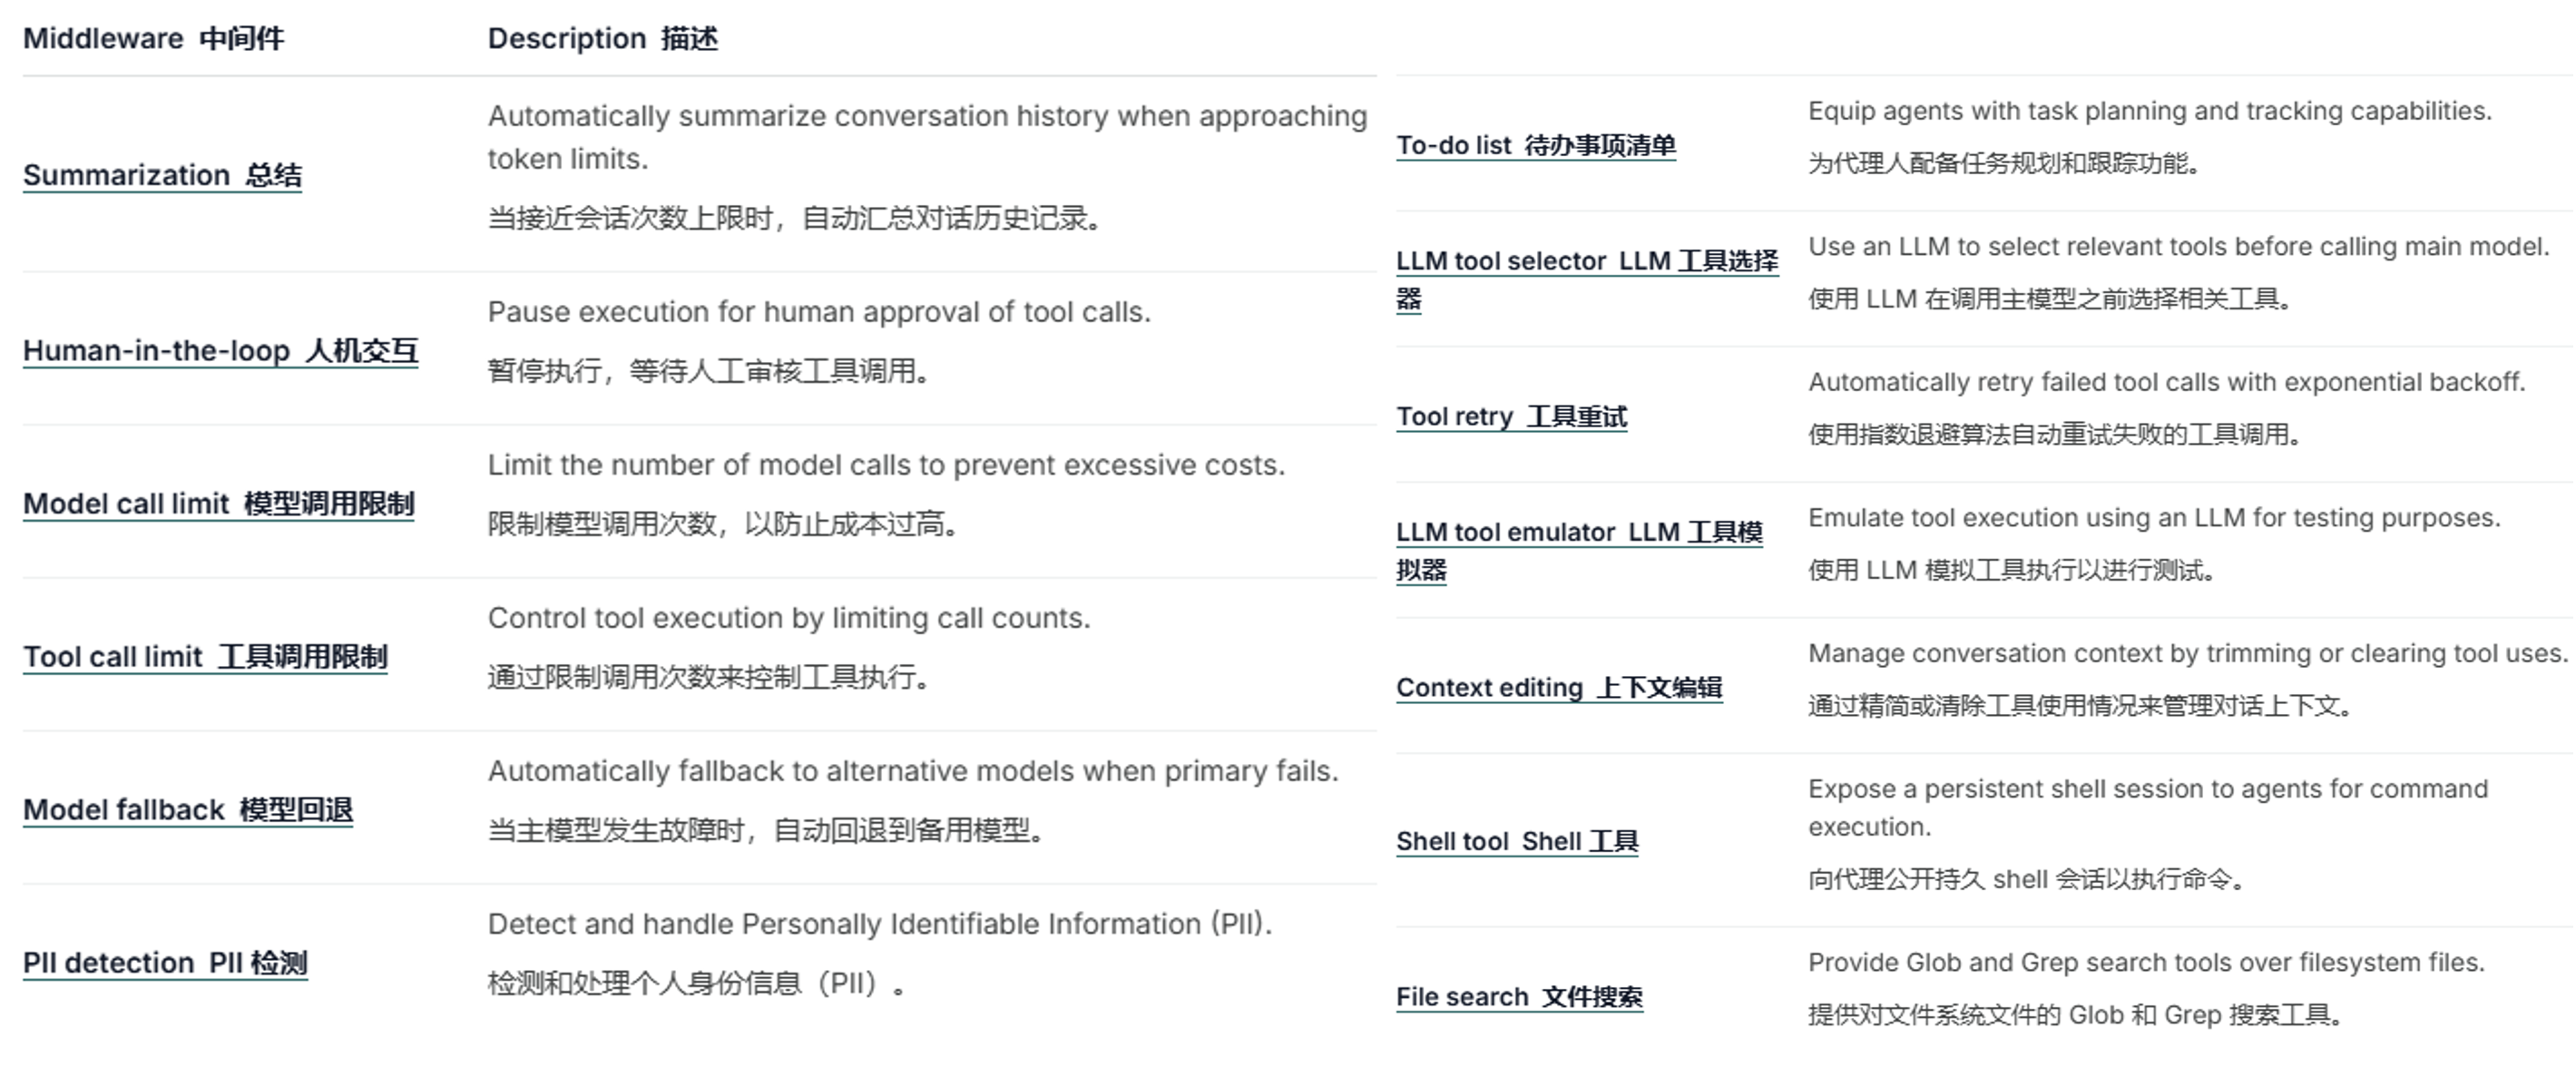

SummarizationMiddleware 摘要中间件
- 作用：当接近会话次数上限时，自动生成会话摘要，减少token消耗
- 非常适合：
    - 持续时间过长的对话超出了上下文窗口。
    - 多轮对话，历史悠久
    - 在需要保留完整对话上下文的应用中

In [1]:
from langchain_core.messages import HumanMessage
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents.middleware import SummarizationMiddleware

llm = init_chat_model("deepseek-flash")
memory = InMemorySaver()
agent = create_agent(
    model=llm,
    tools=[],
    checkpointer=memory,
    # 中间件列表，可以多个，多个顺序执行
    middleware=[
        SummarizationMiddleware(
            model=llm,
            max_tokens_before_summary=80,  # 80个token 会触发 摘要总结
            messages_to_keep=1,  # 在总结后保留最后1条消息
            # 可选 summary_prompt=" 可以自定义进行摘要的提示词...",
            summary_prompt="请将以下对话历史进行简洁的摘要，保留关键信息: {messages}"
        ),
    ],
    # 打印Agent执行的过程日志
    debug= True
)

# 单一条件:当tokens> = 4000且消息> = 10时触发
# agent = create_agent(
#     model=llm,
#     tools=[weather_tool, add_tool],
#     middleware=[
#         SummarizationMiddleware(
#             model=llm_other,
#             trigger={"tokens": 4000, "messages": 10},
#             keep={"messages": 20},
#         ),
#     ],
# )
#
# # 多重条件-（任意条件必须满足 - 逻辑“或”）。
# agent2 = create_agent(
#     model="gpt-4o",
#     tools=[weather_tool, add_tool],
#     middleware=[
#         SummarizationMiddleware(
#             model="gpt-4o-mini",
#             trigger=[
#                 {"tokens": 5000, "messages": 3},
#                 {"tokens": 3000, "messages": 6},
#             ],
#             keep={"messages": 20},
#         ),
#     ],
# )

# 模拟长对话触发摘要
print("\n模拟长对话场景...")
demo_messages = [
    "用户询问你是谁",
    "用户计算商品价格：数量10，单价25.5",
    "用户再次询问你能做什么？",
    "用户想要生成一个介绍湖南的文案，要求100字左右，包含三湘四水，人文历史",
    "用户继续询问更多GPU产品信息",
    "用户要求计算2*20"
]

for i, message in enumerate(demo_messages, 1):
    print(f"\n💬 第{i}轮对话: {message}")
    # 循环调用Agent，模拟多轮对话
    result = agent.invoke({
        "messages": [HumanMessage(content=message)]},
        config={"configurable": {"thread_id": "testsummarizationMiddleware"}}
    )
    # print("执行结果："+result)

C:\Users\user\AppData\Local\Temp\ipykernel_61724\4088739103.py:22: DeprecationWarning: max_tokens_before_summary is deprecated. Use trigger=('tokens', value) instead.
  SummarizationMiddleware(
C:\Users\user\AppData\Local\Temp\ipykernel_61724\4088739103.py:22: DeprecationWarning: messages_to_keep is deprecated. Use keep=('messages', value) instead.
  SummarizationMiddleware(



模拟长对话场景...

💬 第1轮对话: 用户询问你是谁
[values] {'messages': [HumanMessage(content='用户询问你是谁', additional_kwargs={}, response_metadata={}, id='4b3cf974-19fb-436d-a27c-b673a790a20d')]}
[updates] {'SummarizationMiddleware.before_model': None}
[updates] {'model': {'messages': [AIMessage(content='我是 **DeepSeek**，由深度求索公司创造的 AI 助手。我可以帮你回答问题、处理文本、分析文件、编写代码、进行推理等。\n\n我支持多模态识别，可以接收你上传的图片，并从中提取文字信息。我也可以阅读上传的文件（如图片、PDF、Word、Excel、PPT 等）并处理其中的文字内容。需要联网搜索时，你可以在 Web 或 App 中手动开启联网搜索功能。\n\n有什么我可以帮你的吗？', additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答用户“用户询问你是谁”。这可能是用户直接问“你是谁”。需要用中文回答。需要表明身份：我是 DeepSeek，由深度求索公司创造的 AI 助手。可以简要说明能力、免费、支持文件上传、联网搜索（需手动开启）等。注意不要声称自己是人类。保持友好。可能需要根据上下文？用户只说了“用户询问你是谁”，这像指令要求我回答“你是谁”。我应该直接回答。可以包括版本？当前模型是 DeepSeek？知识截止 2026-02？系统说当前日期 2026-05-10，但模型知识截止 2026-02。可以介绍。不要过度长。最终回答。'}, response_metadata={'token_usage': {'completion_tokens': 248, 'prompt_tokens': 33, 'total_tokens': 281, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'rea

In [2]:
for i, message in enumerate(demo_messages, 1):
    print(f"\n💬 第{i}轮对话: {message}")


💬 第1轮对话: 用户询问你是谁

💬 第2轮对话: 用户计算商品价格：数量10，单价25.5

💬 第3轮对话: 用户再次询问你能做什么？

💬 第4轮对话: 用户想要生成一个介绍湖南的文案，要求100字左右，包含三湘四水，人文历史

💬 第5轮对话: 用户继续询问更多GPU产品信息

💬 第6轮对话: 用户要求计算2*20


### 2. 自定义中间件

#### 2.1 两大 Hook 家族
| 家族 | 钩子 | 触发时机 | 次数 | 是否新增图节点 |
| ---- | ---- | ---- | ---- | ---- |
| **Node 型** | `before_agent` | Agent 开始执行前 | 每次 invoke 一次 | ✅ 变成真实节点 |
| | `before_model` | 每次模型调用**前** | 每轮循环多次 | ✅ 变成真实节点 |
| | `after_model` | 每次模型响应**后** | 每轮循环多次 | ✅ 变成真实节点 |
| | `after_agent` | Agent 执行结束后 | 每次 invoke 一次 | ✅ 变成真实节点 |
| **Wrap 型**| `wrap_model_call` | 包裹每次模型调用 | 每轮循环多次 | ❌ 不新增节点 |
| | `wrap_tool_call` | 包裹每次工具调用 | 每次工具调用 | ❌ 不新增节点 |
| **便捷型** | `dynamic_prompt` | 动态生成 system prompt | — | ✅ 变真实节点 |

### 2.2 两种写法
| 写法 | 适用场景 | 特点 |
| ---- | ---- | ---- |
| **装饰器式** | 单个 hook、无复杂配置、快速原型 | `@before_model` / `@wrap_model_call` 等，一个函数搞定 |
| **类式** | 多个 hook 组合、需要初始化配置、要复用 | 继承 `AgentMiddleware`，重写多个钩子方法，可同时定义同步+异步版本 |


区别记忆：**Node 型钩子是「运行在步骤之间」的独立节点，能改状态、能跳转（jump_to）；Wrap 型钩子是「包裹在调用外」的函数，靠 `handler(request)` 决定调用执行几次（0 次/1 次/多次），能重试、能短路、能改请求。**

类式中间件

In [13]:
import os
from langchain.agents.middleware import AgentMiddleware
from langchain.agents.middleware import AgentState
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.runtime import Runtime
from typing import Any
import time

class LoggingMiddleware(AgentMiddleware):
    def before_model(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        self._start_time = time.time()          # 用 self 在钩子间共享状态
        print(f"即将调用模型： {len(state['messages'])} 个消息")
        return None

    def after_model(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        print(f"本次模型调用耗时 {time.time() - self._start_time:.2f}s")
        print(f"模型返回消息: {state['messages'][-1].content}")

        return None

llm = ChatOpenAI(api_key=os.getenv("DASHSCOPE_API_KEY"), model="qwen-max",base_url="https://dashscope.aliyuncs.com/compatible-mode/v1")

agent = create_agent(
    model=llm,
    middleware=[LoggingMiddleware()],
)
result = agent.invoke({"messages": [{"role": "user","content": "你好",}]})
print(result)

即将调用模型： 1 个消息
本次模型调用耗时 0.49s
模型返回消息: 你好！有什么可以帮助你的吗？
{'messages': [HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='3689342d-46dc-468d-97cc-0e6eb89f98d2'), AIMessage(content='你好！有什么可以帮助你的吗？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 7, 'prompt_tokens': 9, 'total_tokens': 16, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'qwen-max', 'system_fingerprint': None, 'id': 'chatcmpl-8324b831-7d88-9692-b80c-9d4ffae4ed3d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a129e4-f162-73d2-933e-36523a067f71-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 7, 'total_tokens': 16, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})]}


装饰器中间件

In [10]:
import os
from langchain.agents.middleware import before_model, wrap_model_call
from langchain.agents.middleware import AgentState, ModelRequest, ModelResponse
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.runtime import Runtime
from typing import Any, Callable

# 前置，在调用模型前，执行这个函数
@before_model
def log_before_model(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    print(f"即将调用模型： {len(state['messages'])} 个消息")
    return None

# wrap_model_call 环绕，在model调用前后都执行这个函数
@wrap_model_call
def round_model(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
        print(f"模型调用前置处理 request： request={request}")
        print(f"模型调用前置处理 handler： handler={handler}")
        result = handler(request)  # 调用模型

        print(f"模型调用后，模型返回结果： {result}")
        return result

llm = ChatOpenAI(api_key=os.getenv("DASHSCOPE_API_KEY"), model="qwen-max",base_url="https://dashscope.aliyuncs.com/compatible-mode/v1")

agent = create_agent(
    model=llm,
    # 按照列表顺序依次执行中间件
    middleware=[log_before_model, round_model],
)
result = agent.invoke({"messages": [{"role": "user", "content": "你好",}]})

即将调用模型： 1 个消息
模型调用前置处理 request： request=ModelRequest(model=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4', 'langchain-openai': '1.7.0'}}, client=<openai.resources.chat.completions.completions.Completions object at 0x00000208DD93C830>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x00000208DD98C710>, root_client=<openai.OpenAI object at 0x00000208DD93F200>, root_async_client=<openai.AsyncOpenAI object at 0x00000208DD93E660>, model_name='qwen-max', model_kwargs={}, openai_api_key=SecretStr('**********'), openai_api_base='https://dashscope.aliyuncs.com/compatible-mode/v1', stream_chunk_timeout=120.0), messages=[HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='c6d5a20d-83ec-40ff-8001-df0a507d8462')], system_message=None, tool_choice=None, tools=[], response_format=None, state={'messages': [HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='c6d5a20d-83ec-40ff-800